# 04 — Feature engineering

**Objectif** : transformer les constats de l'EDA en **variables explicatives**, les implémenter dans un pipeline réutilisable, puis évaluer leur **pouvoir discriminant**, leur **redondance** et leur **stabilité dans le temps**.

**Principes**
- Toutes les variables sont calculées par `FraudFeatureBuilder` (`src/features.py`), un transformer scikit-learn **sans état** : chaque variable ne dépend que de la transaction elle-même, ce qui exclut toute fuite d'information entre jeux de données.
- Le même pipeline sera utilisé à l'entraînement, à l'évaluation et dans la démo Streamlit.
- Toutes les analyses de ce notebook sont faites sur le **jeu d'entraînement uniquement** (sauf l'analyse de stabilité, qui compare précisément les jeux entre eux).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

from src.config import RANDOM_STATE, TARGET, SPLIT_NAMES
from src.data import load_data
from src.split import load_split, filter_fraud_types
from src.features import (build_preprocessor, FEATURE_SETS, TRANSACTION_FEATURES,
                          BALANCE_FEATURES)
from src.stats import population_stability_index
from src.viz import set_style, save_fig, COLOR_LEGIT, TEXT_SECONDARY, SEQUENTIAL_CMAP

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

splits = {name: load_split(name) for name in SPLIT_NAMES}
for name, part in splits.items():
    print(f"{name:<6} {len(part):>10,} transactions  {part[TARGET].sum():>5,} fraudes")

train   1,917,584 transactions  3,511 fraudes
val       346,348 transactions    498 fraudes
test      349,818 transactions    570 fraudes
drift     156,659 transactions  3,634 fraudes


## 1. Construction des variables

| Famille | Variable | Construction | Origine |
|---|---|---|---|
| Transaction | `is_transfer` | 1 si TRANSFER, 0 si CASH_OUT | H1 |
| Transaction | `log_amount` | log(1 + montant) | H2 |
| Transaction | `heure_sin`, `heure_cos` | encodage **cyclique** de l'heure | H5 |
| Transaction | `is_night` | 1 entre 0h et 6h | H5 |
| Soldes | `log_oldbalanceOrig`, `log_newbalanceOrig`, `log_oldbalanceDest`, `log_newbalanceDest` | soldes en échelle log | — |
| Soldes | `erreur_orig`, `erreur_dest` | écart entre solde attendu et observé (log signé) | H4 |
| Soldes | `compte_vide` | montant = solde initial > 0 | H3 |
| Soldes | `orig_solde_nul` | solde émetteur initial nul | Phase 2 |
| Soldes | `dest_soldes_nuls` | soldes destinataire nuls avant et après | EDA §6 |
| Soldes | `ratio_montant_solde` | log(1 + montant / (solde initial + 1)) | H3 |

**Choix techniques justifiés**
- **Échelle log** : montants et soldes couvrent 8 ordres de grandeur ; le log rend les distributions exploitables par un modèle linéaire (les arbres y sont insensibles).
- **Log signé** pour les erreurs de solde, qui peuvent être négatives : on compresse l'amplitude sans perdre le sens de l'écart.
- **Encodage cyclique de l'heure** : avec un entier 0-23, 23h et 0h semblent très éloignées alors qu'elles sont voisines. Le couple (sin, cos) place les heures sur un cercle.
- **Exclusions** : `isFlaggedFraud` (règle métier, utilisée seulement comme baseline), `nameOrig` / `nameDest` (identifiants), `step` brut (non stationnaire : le modèle apprendrait des jours précis, sans valeur pour le futur).

In [2]:
preprocessor = build_preprocessor("complet").fit(splits["train"])
X_train = preprocessor.transform(splits["train"])
y_train = splits["train"][TARGET].to_numpy()
print(f"Matrice d'entraînement : {X_train.shape[0]:,} lignes x {X_train.shape[1]} variables")
X_train.head()

Matrice d'entraînement : 1,917,584 lignes x 15 variables


,is_transfer,log_amount,heure_sin,heure_cos,is_night,log_oldbalanceOrig,log_newbalanceOrig,log_oldbalanceDest,log_newbalanceDest,erreur_orig,erreur_dest,compte_vide,orig_solde_nul,dest_soldes_nuls,ratio_montant_solde
0,1,5.2040,0.2588,0.9659,1,5.2040,0.0000,0.0000,0.0000,0.0000,5.2040,1,0,1,0.6904
1,0,5.2040,0.2588,0.9659,1,5.2040,0.0000,9.9610,0.0000,0.0000,9.9695,1,0,0,0.6904
2,0,12.3421,0.2588,0.9659,1,9.6373,0.0000,8.5339,10.8496,12.2728,12.1156,0,0,0,2.7695
3,1,12.2798,0.2588,0.9659,1,6.5596,0.0000,10.0180,0.0000,12.2766,12.3789,0,0,0,5.7235
4,1,12.6498,0.2588,0.9659,1,9.2906,0.0000,8.7432,14.8158,12.6144,-14.6915,0,0,0,3.3933


In [3]:
X_train.groupby(y_train).mean().T.rename(columns={0: "moyenne légitime", 1: "moyenne fraude"})

,moyenne légitime,moyenne fraude
is_transfer,0.1884,0.4973
log_amount,11.9113,12.8364
heure_sin,-0.4552,-0.0264
heure_cos,-0.3537,-0.0293
is_night,0.0092,0.2558
log_oldbalanceOrig,5.2301,12.7528
log_newbalanceOrig,1.1104,0.1977
log_oldbalanceDest,11.6013,4.5138
log_newbalanceDest,13.5263,6.9187
erreur_orig,10.6891,0.1131


## 2. Pouvoir discriminant univarié

Pour chaque variable prise **seule**, on mesure sa capacité à classer les fraudes devant les transactions légitimes :
- **ROC-AUC** : 0,5 = hasard, 1 = séparation parfaite ;
- **PR-AUC** (average precision) : à comparer au taux de fraude du train (~0,18 %), qui est la valeur obtenue au hasard.

Une variable dont l'AUC est inférieure à 0,5 est discriminante « à l'envers » : on inverse son signe pour la mesure.

In [4]:
rows = []
for col in X_train.columns:
    x = X_train[col].to_numpy(dtype=float)
    auc = roc_auc_score(y_train, x)
    sens = 1 if auc >= 0.5 else -1
    rows.append({
        "variable": col,
        "famille": "transaction" if col in TRANSACTION_FEATURES else "soldes",
        "sens": "+" if sens == 1 else "−",
        "roc_auc": max(auc, 1 - auc),
        "pr_auc": average_precision_score(y_train, sens * x),
    })
power = pd.DataFrame(rows).set_index("variable").sort_values("pr_auc", ascending=False)
print(f"PR-AUC d'un classement aléatoire : {y_train.mean():.4f}")
power

PR-AUC d'un classement aléatoire : 0.0018


,famille,sens,roc_auc,pr_auc
variable,,,,
compte_vide,soldes,+,0.9893,0.9787
dest_soldes_nuls,soldes,+,0.7444,0.2561
log_oldbalanceOrig,soldes,+,0.9210,0.2115
erreur_dest,soldes,+,0.7470,0.1693
log_newbalanceDest,soldes,−,0.7303,0.0675
heure_sin,transaction,+,0.6752,0.0313
erreur_orig,soldes,−,0.9446,0.0189
is_night,transaction,+,0.6233,0.0138
log_amount,transaction,+,0.6764,0.0132


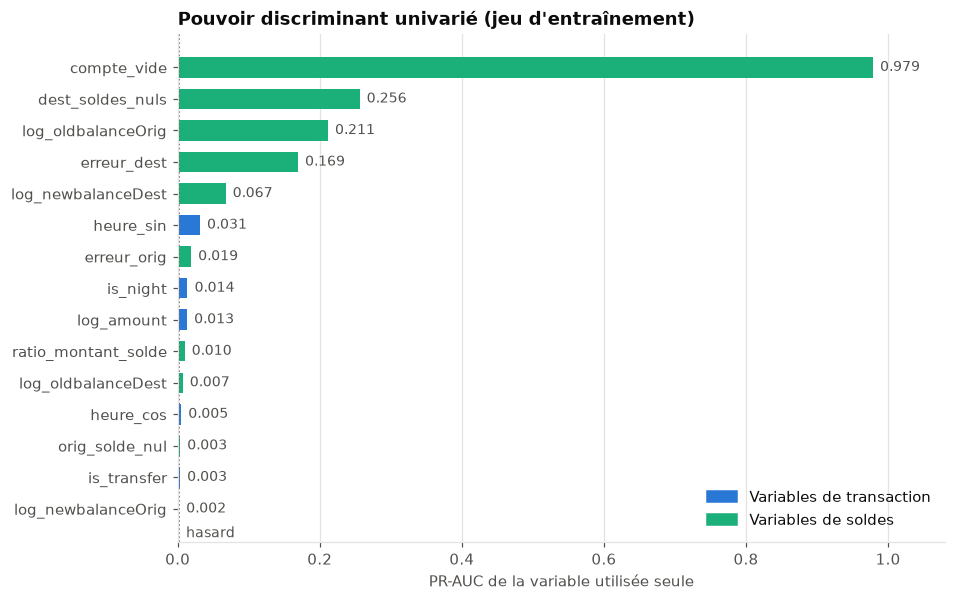

In [5]:
family_colors = {"transaction": COLOR_LEGIT, "soldes": "#1baf7a"}
plot_df = power.sort_values("pr_auc")
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df.index, plot_df["pr_auc"], color=plot_df["famille"].map(family_colors), height=0.65)
ax.axvline(y_train.mean(), color=TEXT_SECONDARY, linestyle=":", linewidth=1)
ax.text(y_train.mean() + 0.01, -0.9, "hasard", color=TEXT_SECONDARY, fontsize=9)
for i, v in enumerate(plot_df["pr_auc"]):
    ax.text(v + 0.01, i, f"{v:.3f}", va="center", fontsize=9, color=TEXT_SECONDARY)
ax.set_xlim(0, 1.08)
ax.set_xlabel("PR-AUC de la variable utilisée seule")
ax.set_title("Pouvoir discriminant univarié (jeu d'entraînement)")
ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in family_colors.values()]
ax.legend(handles, ["Variables de transaction", "Variables de soldes"], loc="lower right")
save_fig(fig, "04_pouvoir_discriminant")
plt.show()

**Interprétation**
- **`compte_vide` écrase tout** : à elle seule, elle atteint une PR-AUC de **0,979**. C'est la traduction directe de l'artefact identifié en H3 (aucune transaction légitime ne vide le compte). Les autres variables de soldes (`dest_soldes_nuls`, `log_oldbalanceOrig`, `erreur_dest`) suivent, avec des PR-AUC de 0,17 à 0,26.
- **Les variables de transaction sont faibles prises seules** (PR-AUC ≤ 0,03), mais restent **2 à 17 fois au-dessus du hasard** (0,0018). Combinées dans un modèle, elles peuvent apporter un signal réel : c'est ce que mesurera le jeu de variables `transaction`.
- **ROC-AUC et PR-AUC peuvent diverger fortement** : `erreur_orig` a une ROC-AUC de 0,94 mais une PR-AUC de seulement 0,019. Presque toutes les fraudes ont une erreur nulle, mais ~180 000 transactions légitimes aussi : la variable classe bien les fraudes *globalement* (ROC élevée) mais produit énormément de fausses alertes en tête de classement (PR faible). C'est l'illustration concrète du choix de la PR-AUC comme métrique principale (cadrage, §6).

⚠️ L'analyse univariée ne dit rien des **interactions** : une variable faible seule peut être utile combinée à d'autres. Aucune variable n'est donc éliminée à ce stade ; l'importance réelle sera mesurée avec SHAP (Phase 9).

## 3. Redondance entre variables

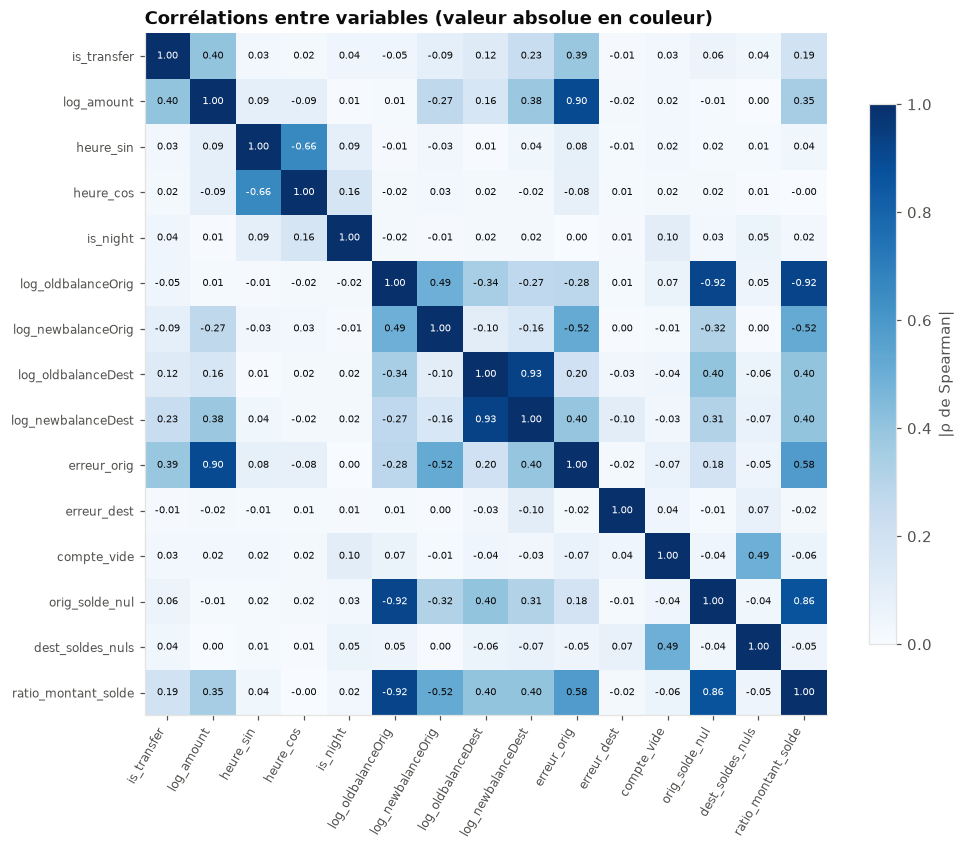

,variable_1,variable_2,rho
113,log_oldbalanceDest,log_newbalanceDest,0.9295
89,log_oldbalanceOrig,ratio_montant_solde,-0.9181
87,log_oldbalanceOrig,orig_solde_nul,-0.9160
24,log_amount,erreur_orig,0.8965
194,orig_solde_nul,ratio_montant_solde,0.8639


In [6]:
sample = X_train.sample(n=300_000, random_state=RANDOM_STATE)
corr = sample.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr.abs(), cmap=SEQUENTIAL_CMAP, vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.75, label="|ρ de Spearman|")
ax.set_title("Corrélations entre variables (valeur absolue en couleur)")
save_fig(fig, "04_correlations_variables")
plt.show()

pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().rename(columns={"level_0": "variable_1", "level_1": "variable_2"}))
pairs[pairs["rho"].abs() > 0.8].sort_values("rho", key=abs, ascending=False)

**Interprétation** : cinq paires dépassent |ρ| = 0,8, toutes attendues par construction (soldes destinataire avant/après, solde émetteur et ratio montant/solde, montant et erreur émetteur).

**Décision : aucune suppression à ce stade.**
- Les modèles à base d'arbres (Random Forest, boosting) sont peu sensibles à la colinéarité ;
- Pour la régression logistique, la **régularisation L2** limite l'instabilité des coefficients ;
- La redondance pourra être réexaminée après l'analyse SHAP si elle nuit à l'interprétabilité.

## 4. Stabilité des variables dans le temps (PSI)

L'**indice de stabilité de population** (PSI), standard dans le secteur bancaire, mesure la dérive de la distribution d'une variable entre le train et un autre jeu :
- PSI < 0,1 : stable ;
- 0,1 – 0,25 : dérive modérée ;
- PSI > 0,25 : dérive importante.

Une variable instable fragilise le modèle : ce qu'il a appris sur le train ne s'applique plus de la même façon.

In [7]:
X = {name: preprocessor.transform(part) for name, part in splits.items()}
psi = pd.DataFrame({
    f"train → {name}": {col: population_stability_index(X["train"][col], X[name][col]) for col in X_train.columns}
    for name in ["val", "test", "drift"]
})
psi.style.format("{:.3f}").background_gradient(cmap="Oranges", vmin=0, vmax=0.5)

,train → val,train → test,train → drift
is_transfer,0.000,0.000,0.010
log_amount,0.008,0.001,0.002
heure_sin,0.004,0.005,0.107
heure_cos,0.003,0.007,0.175
is_night,0.001,0.000,0.033
log_oldbalanceOrig,0.000,0.000,0.022
log_newbalanceOrig,0.000,0.000,0.000
log_oldbalanceDest,0.006,0.004,0.012
log_newbalanceDest,0.010,0.005,0.012
erreur_orig,0.009,0.001,0.010


In [8]:
def level(v):
    return "stable" if v < 0.1 else ("modérée" if v < 0.25 else "importante")
psi.map(level).apply(pd.Series.value_counts).fillna(0).astype(int)

,train → val,train → test,train → drift
modérée,0,0,3
stable,15,15,12


**Interprétation**
- **Train → val et train → test : les 15 variables sont stables** (PSI ≤ 0,09). C'est une validation directe du protocole de la Phase 4 : val et test ressemblent bien aux conditions d'entraînement.
- **Train → drift : trois variables dérivent modérément** : `heure_cos` (0,18), `erreur_dest` (0,16) et `heure_sin` (0,11). C'est cohérent avec la période anormale : la répartition horaire de l'activité y est différente et la part de fraudes est 13 fois plus élevée, ce qui modifie la distribution des erreurs côté destinataire.
- Aucune variable n'atteint une dérive importante (> 0,25), même sur le jeu de drift.

➡️ En production, ce même calcul de PSI servirait d'**indicateur de surveillance** : une dérive importante déclencherait une alerte et un réentraînement.

## 5. Variable écartée : l'historique du destinataire

Les émetteurs étant quasi uniques, seul le **destinataire** possède un historique. On a testé une variable comptant le **nombre de transactions déjà reçues** par le destinataire avant la transaction courante (calculée chronologiquement, sans information future).

In [9]:
full = load_data()[["step", "type", "nameDest", "isFraud"]].sort_values("step", kind="stable")
full["n_recues_avant"] = full.groupby("nameDest").cumcount()
hist = filter_fraud_types(full)
auc_hist = roc_auc_score(hist["isFraud"], -hist["n_recues_avant"])
ap_hist = average_precision_score(hist["isFraud"], -hist["n_recues_avant"])
print(f"ROC-AUC : {auc_hist:.3f}  |  PR-AUC : {ap_hist:.4f}  (hasard : {hist['isFraud'].mean():.4f})")
hist.groupby("isFraud")["n_recues_avant"].describe()

ROC-AUC : 0.769  |  PR-AUC : 0.0103  (hasard : 0.0030)


,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,"2,762,196.0000",7.7352,8.6142,0.0000,2.0000,5.0000,11.0000,112.0000
1,"8,213.0000",2.7013,5.9842,0.0000,0.0000,0.0000,3.0000,61.0000


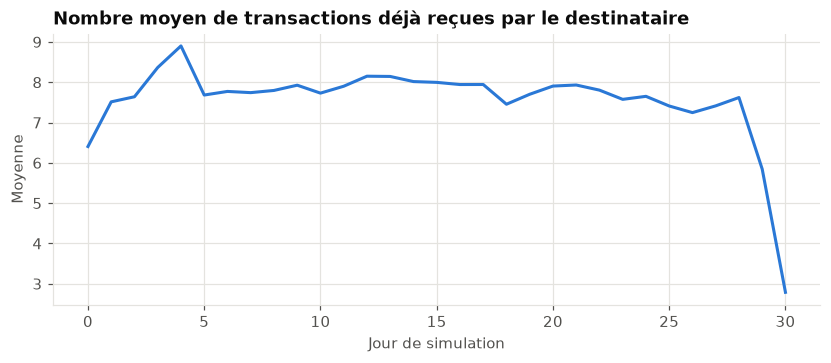

In [10]:
by_day = hist.assign(jour=hist["step"] // 24).groupby("jour")["n_recues_avant"].mean()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(by_day.index, by_day.values, color=COLOR_LEGIT)
ax.set_xlabel("Jour de simulation")
ax.set_ylabel("Moyenne")
ax.set_title("Nombre moyen de transactions déjà reçues par le destinataire")
save_fig(fig, "04_historique_destinataire")
plt.show()

**Décision : variable écartée**, pour trois raisons :
1. **Gain limité** : ROC-AUC correcte mais PR-AUC très faible, bien en dessous des variables de soldes ;
2. **Non stationnaire par construction** : le compteur augmente mécaniquement avec le temps écoulé depuis le début de la simulation (graphique ci-dessus). Le modèle apprendrait une relation qui change d'un jour à l'autre ;
3. **Coût d'industrialisation** : elle exige de maintenir un historique de tous les comptes, ce qui sort du périmètre de la démo.

Elle est mentionnée comme **perspective** : sur des données réelles, des variables comportementales sur fenêtre glissante (nombre de transactions reçues sur les dernières 24 h, par exemple) seraient au contraire essentielles.

## 6. Deux jeux de variables pour l'étude de robustesse

In [11]:
pd.DataFrame({name: pd.Series(cols) for name, cols in FEATURE_SETS.items()}).fillna("")

,complet,transaction
0,is_transfer,is_transfer
1,log_amount,log_amount
2,heure_sin,heure_sin
3,heure_cos,heure_cos
4,is_night,is_night
5,log_oldbalanceOrig,
6,log_newbalanceOrig,
7,log_oldbalanceDest,
8,log_newbalanceDest,
9,erreur_orig,


- **`complet`** (15 variables) : toutes les variables, utilisé pour le modèle principal ;
- **`transaction`** (5 variables) : uniquement type, montant et heure, **sans aucune variable de solde**.

Comparer les deux en Phase 7 permettra de chiffrer la part de la performance qui repose sur les mécanismes de soldes du simulateur, et donc d'évaluer la **transposabilité** du modèle à des données réelles.

## 7. Conclusions

- **15 variables** construites à partir des constats de l'EDA, implémentées dans un **pipeline scikit-learn** (`build_preprocessor`) sans état, testé unitairement (47 tests) et réutilisable tel quel dans la démo.
- **Pouvoir discriminant** : les variables de soldes dominent, avec une variable quasi parfaite (`compte_vide`, PR-AUC 0,98) issue d'un artefact du simulateur. Les variables de transaction sont faibles seules mais nettement au-dessus du hasard.
- **Redondance** : quelques corrélations fortes attendues, sans suppression (modèles robustes ou régularisés).
- **Stabilité** : toutes les variables sont stables entre train, val et test, ce qui valide le protocole. Une dérive modérée apparaît seulement sur le jeu de drift.
- **Variable écartée** : l'historique du destinataire (gain faible, non stationnaire, coûteuse à industrialiser), conservée comme perspective.
- **Deux jeux de variables** (`complet` et `transaction`) prêts pour l'étude de robustesse.

**Étape suivante** : Phase 6, modèles de référence (règles métier `isFlaggedFraud` et `compte_vide`, régression logistique) et module d'évaluation commun.